<a href="https://www.kaggle.com/code/adityarizqiqa/project-akhir-pcvk-kelompok-2-pneumonia?scriptVersionId=373794935" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

1. Deduplikasi Dataset, Stratified Split (70/15/15), & Preprocessing CLAHE

In [1]:
import os
import glob
import shutil
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Deteksi otomatis lokasi dataset di /kaggle/input
INPUT_ROOT = "/kaggle/input"
BASE_SPLIT_DIR = "/kaggle/working/dataset_split"
CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)

# Kumpulkan seluruh file citra unik (menghindari folder duplikat & file sistem macOS)
unique_files = {}
for class_name in CLASSES:
    pattern = os.path.join(INPUT_ROOT, "**", class_name, "*.*")
    for f_path in glob.glob(pattern, recursive=True):
        fname = os.path.basename(f_path)
        if (
            "__MACOSX" not in f_path
            and not fname.startswith("._")
            and fname.lower().endswith((".png", ".jpg", ".jpeg"))
        ):
            # Gunakan nama file sebagai kunci agar duplikat folder tidak terhitung ganda
            unique_files[fname] = (f_path, CLASSES.index(class_name))

all_files = [item[0] for item in unique_files.values()]
all_labels = [item[1] for item in unique_files.values()]

print(f"Total citra unik ditemukan : {len(all_files)}")
print(f"Distribusi Awal -> NORMAL: {all_labels.count(0)} | PNEUMONIA: {all_labels.count(1)}")

# 2. Stratified Split: 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    all_files, all_labels, test_size=0.30, stratify=all_labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# 3. Fungsi preprocessing CLAHE & simpan ke /kaggle/working/dataset_split
def save_preprocessed_split(split_name, files, labels):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    for class_name in CLASSES:
        os.makedirs(os.path.join(BASE_SPLIT_DIR, split_name, class_name), exist_ok=True)
    
    for idx, (src_path, label) in enumerate(zip(files, labels)):
        img_gray = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)
        img_resized = cv2.resize(img_gray, IMG_SIZE)
        img_clahe = clahe.apply(img_resized)
        img_rgb = cv2.cvtColor(img_clahe, cv2.COLOR_GRAY2RGB)
        
        dst_path = os.path.join(BASE_SPLIT_DIR, split_name, CLASSES[label], f"{split_name}_{idx}.jpg")
        cv2.imwrite(dst_path, img_rgb)

    print(f"[{split_name.upper():5s}] Total: {len(files):4d} | NORMAL: {labels.count(0):4d} | PNEUMONIA: {labels.count(1):4d}")

if os.path.exists(BASE_SPLIT_DIR):
    shutil.rmtree(BASE_SPLIT_DIR)

print("\nMenyimpan hasil split & preprocessing CLAHE ke /kaggle/working...")
save_preprocessed_split("train", X_train, y_train)
save_preprocessed_split("val", X_val, y_val)
save_preprocessed_split("test", X_test, y_test)

Total citra unik ditemukan : 5856
Distribusi Awal -> NORMAL: 1583 | PNEUMONIA: 4273

Menyimpan hasil split & preprocessing CLAHE ke /kaggle/working...
[TRAIN] Total: 4099 | NORMAL: 1108 | PNEUMONIA: 2991
[VAL  ] Total:  878 | NORMAL:  237 | PNEUMONIA:  641
[TEST ] Total:  879 | NORMAL:  238 | PNEUMONIA:  641


2. Data Augmentation, Class Weighting, & Pelatihan Model CNN

I0000 00:00:1795583915.766494      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795583930.370759      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 4099 files belonging to 2 classes.
Found 878 files belonging to 2 classes.
Found 879 files belonging to 2 classes.


E0000 00:00:1795583932.476028      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Class Weights -> NORMAL (0): 1.850 | PNEUMONIA (1): 0.685

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 914ms/step - auc: 0.5081 - loss: 0.8415 - sensitivity: 0.6429
Epoch 1: val_auc improved from None to 0.68268, saving model to /kaggle/working/best_pneumonia_model.keras

Epoch 1: finished saving model to /kaggle/working/best_pneumonia_model.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - auc: 0.5541 - loss: 0.7538 - sensitivity: 0.5961 - val_auc: 0.6827 - val_loss: 0.6862 - val_sensitivity: 0.4977
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 896ms/step - auc: 0.6915 - loss: 0.6531 - sensitivity: 0.6704
Epoch 2: val_auc improved from 0.68268 to 0.85621, saving model to /kaggle/working/best_pneumonia_model.keras

Epoch 2: finished saving model to /kaggle/working/best_pneumonia_model.keras
129/129 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - auc: 0.7136 - loss: 0.6215 - sensitivity: 0.6747 - val_auc: 0.8562 - val_loss: 0.5316 - val_sensitivity: 0.74

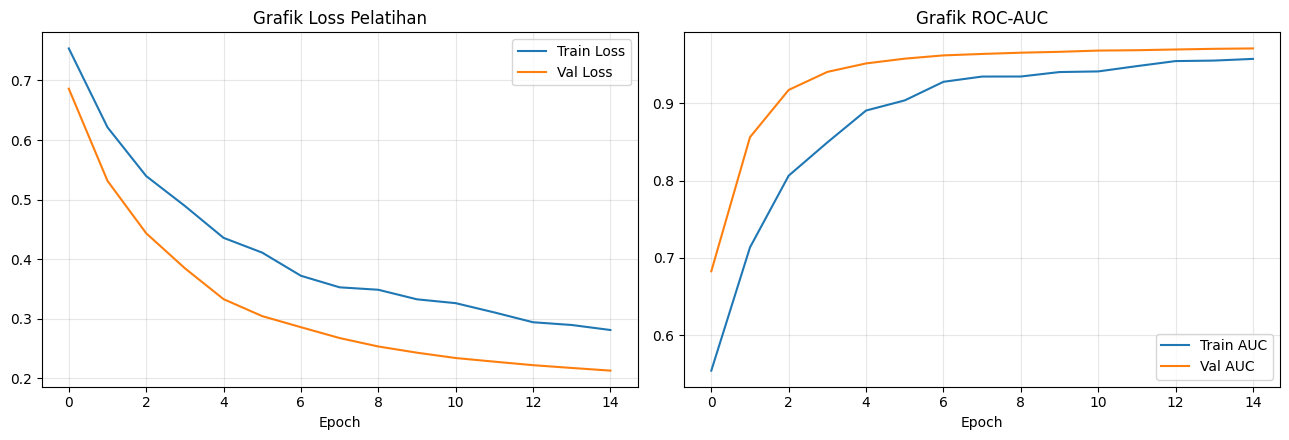

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt

BATCH_SIZE = 32
EPOCHS = 15

# 1. Memuat dataset dari /kaggle/working/dataset_split
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_SPLIT_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_SPLIT_DIR, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_SPLIT_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Optimasi performa pembacaan data dengan prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# 2. Menghitung Class Weight otomatis dari y_train
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {0: weights[0], 1: weights[1]}
print(f"Class Weights -> NORMAL (0): {weights[0]:.3f} | PNEUMONIA (1): {weights[1]:.3f}\n")

# 3. Augmentasi aman medis (hanya diterapkan saat training)
medically_safe_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.04),          # Rotasi ringan sekitar +-14 derajat
    layers.RandomZoom(0.10),              # Zoom maksimal 10%
    layers.RandomTranslation(0.08, 0.08), # Geser posisi maksimal 8%
    layers.RandomContrast(0.10)           # Variasi kontras ringan
], name="xray_augmentation")

# 4. Membangun arsitektur MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = medically_safe_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Recall(name="sensitivity"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 5. Callbacks untuk menyimpan model terbaik di Kaggle
my_callbacks = [
    callbacks.ModelCheckpoint(
        filepath="/kaggle/working/best_pneumonia_model.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=4,
        restore_best_weights=True
    )
]

# 6. Melatih model dengan class_weight
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=my_callbacks
)

# 7. Plot & simpan grafik riwayat training
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Grafik Loss Pelatihan")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("Grafik ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/training_history.png", dpi=300)
plt.show()

3. Evaluasi Sistem Screening, Kurva ROC, & Confusion Matrix

28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 684ms/step

================ EVALUASI SCREENING (Threshold = 0.5) ================
ROC-AUC Score            : 0.9748
Sensitivity (Pneumonia)  : 0.9688 (621/641 kasus terdeteksi)
Specificity (Normal)     : 0.8361 (199/238 sehat terdeteksi)
False Negatives (Bahaya) : 20 pasien pneumonia terlewat
-------------------------------------------------------------------------
              precision    recall  f1-score   support

      NORMAL       0.91      0.84      0.87       238
   PNEUMONIA       0.94      0.97      0.95       641

    accuracy                           0.93       879
   macro avg       0.92      0.90      0.91       879
weighted avg       0.93      0.93      0.93       879


================ EVALUASI SCREENING (Threshold = 0.4) ================
ROC-AUC Score            : 0.9748
Sensitivity (Pneumonia)  : 0.9860 (632/641 kasus terdeteksi)
Specificity (Normal)     : 0.7185 (171/238 sehat terdeteksi)
False Negatives (Bahaya) : 9 pasien pneumonia

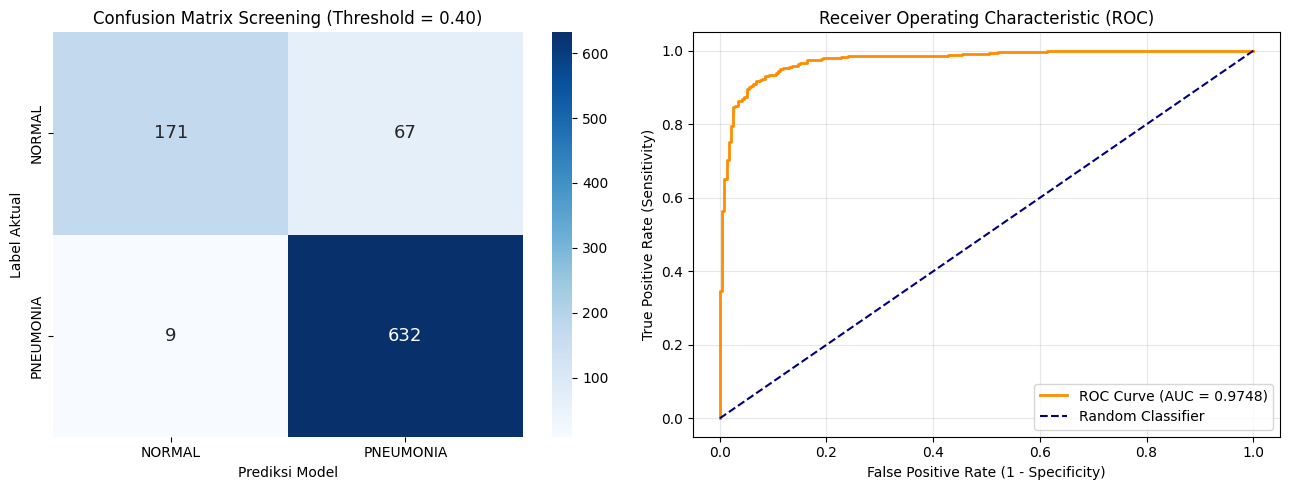

In [3]:
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Ambil probabilitas prediksi pada data test
y_true = np.concatenate([y for x, y in test_ds], axis=0).flatten()
y_probs = model.predict(test_ds).flatten()

def print_screening_metrics(y_true, y_probs, threshold=0.40):
    y_pred = (y_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    auc_score = roc_auc_score(y_true, y_probs)

    print(f"\n================ EVALUASI SCREENING (Threshold = {threshold}) ================")
    print(f"ROC-AUC Score            : {auc_score:.4f}")
    print(f"Sensitivity (Pneumonia)  : {sensitivity:.4f} ({tp}/{tp+fn} kasus terdeteksi)")
    print(f"Specificity (Normal)     : {specificity:.4f} ({tn}/{tn+fp} sehat terdeteksi)")
    print(f"False Negatives (Bahaya) : {fn} pasien pneumonia terlewat")
    print("-" * 73)
    print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"]))
    return confusion_matrix(y_true, y_pred)

cm_default = print_screening_metrics(y_true, y_probs, threshold=0.50)
cm_screening = print_screening_metrics(y_true, y_probs, threshold=0.40)

# Visualisasi Confusion Matrix (Threshold 0.40) dan Kurva ROC
fpr, tpr, _ = roc_curve(y_true, y_probs)
auc_val = roc_auc_score(y_true, y_probs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_screening, annot=True, fmt="d", cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"],
    ax=axes[0], annot_kws={"size": 13}
)
axes[0].set_title("Confusion Matrix Screening (Threshold = 0.40)", fontsize=12)
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Label Aktual")

axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC Curve (AUC = {auc_val:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Classifier")
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=12)
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Sensitivity)")
axes[1].legend(loc="lower right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/evaluasi_screening.png", dpi=300)
plt.show()

4. Visualisasi Grad-CAM Heatmap & Penyimpanan Hasil

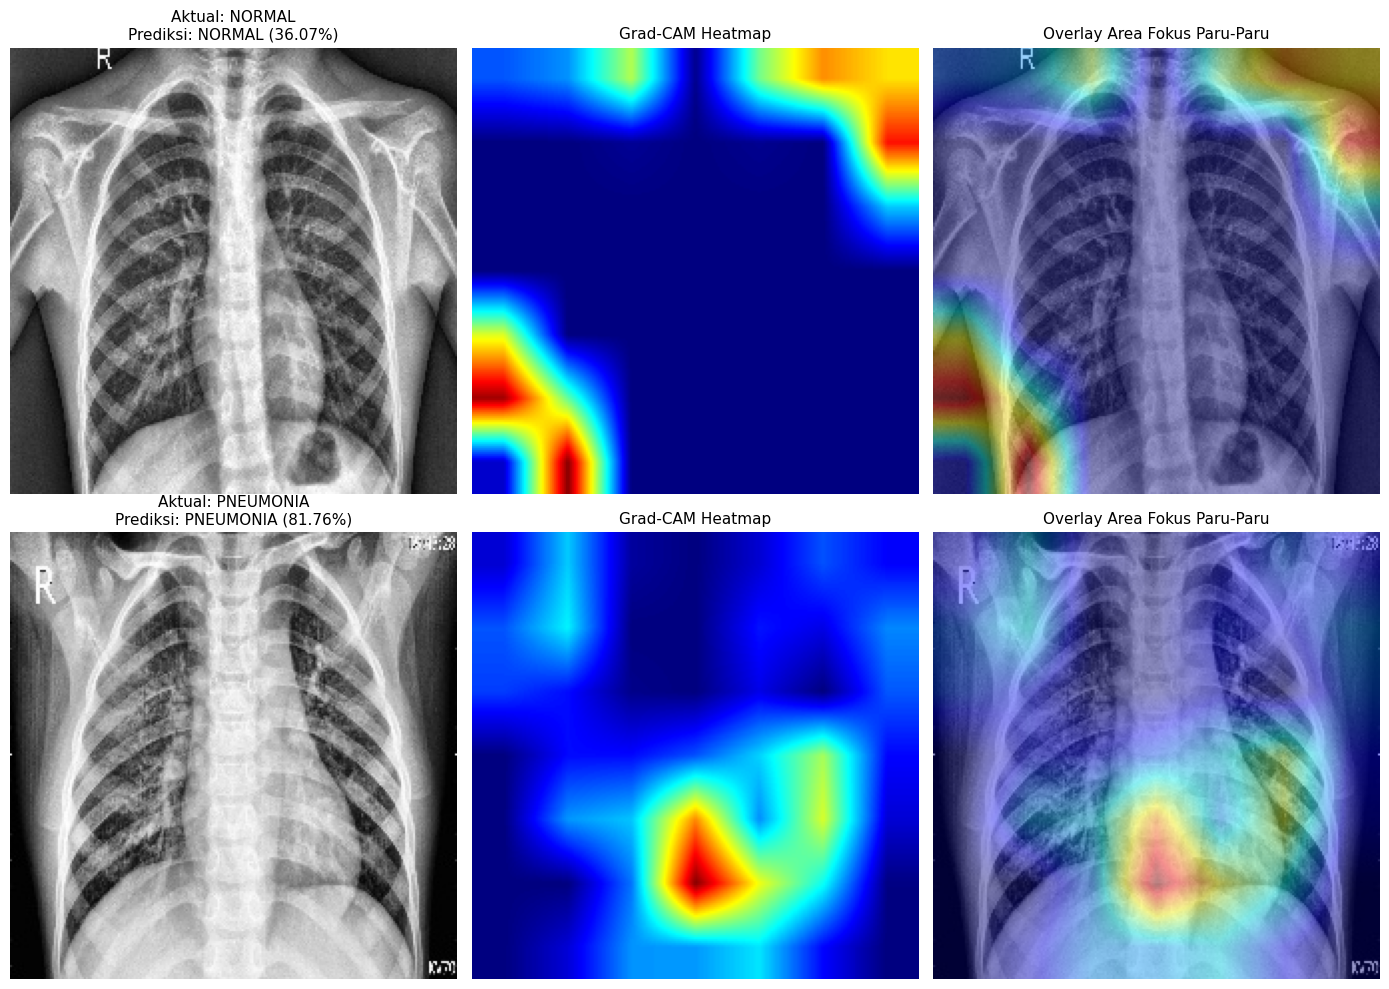

In [4]:
import random

def make_gradcam_heatmap(img_array, base_model, full_model, last_conv_layer_name="out_relu"):
    conv_model = tf.keras.Model(
        inputs=base_model.inputs,
        outputs=base_model.get_layer(last_conv_layer_name).output
    )

    classifier_input = tf.keras.Input(shape=conv_model.output.shape[1:])
    x = classifier_input
    base_idx = [i for i, layer in enumerate(full_model.layers) if layer.name == base_model.name][0]
    for layer in full_model.layers[base_idx + 1:]:
        x = layer(x)
    classifier_model = tf.keras.Model(classifier_input, x)

    with tf.GradientTape() as tape:
        preprocessed_img = tf.keras.applications.mobilenet_v2.preprocess_input(
            tf.cast(img_array, tf.float32)
        )
        conv_outputs = conv_model(preprocessed_img)
        tape.watch(conv_outputs)
        preds = classifier_model(conv_outputs)
        class_channel = preds[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), float(preds[0][0])

def save_and_show_gradcam(test_dir, base_model, full_model, img_size=(224, 224), alpha=0.4):
    random.seed(42)
    sample_paths = []
    for class_name in ["NORMAL", "PNEUMONIA"]:
        files = sorted(glob.glob(f"{test_dir}/{class_name}/*.*"))
        if files:
            sample_paths.append((class_name, random.choice(files)))

    fig, axes = plt.subplots(len(sample_paths), 3, figsize=(14, 5 * len(sample_paths)))
    if len(sample_paths) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, (true_label, img_path) in enumerate(sample_paths):
        orig_bgr = cv2.imread(img_path)
        orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
        orig_resized = cv2.resize(orig_rgb, img_size)

        img_array = np.expand_dims(orig_resized, axis=0)
        heatmap, prob = make_gradcam_heatmap(img_array, base_model, full_model)

        heatmap_resized = cv2.resize(heatmap, img_size)
        heatmap_uint8 = np.uint8(255 * heatmap_resized)
        heatmap_bgr = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
        heatmap_rgb = cv2.cvtColor(heatmap_bgr, cv2.COLOR_BGR2RGB)

        superimposed = np.clip(heatmap_rgb * alpha + orig_resized * (1 - alpha), 0, 255).astype(np.uint8)
        pred_label = "PNEUMONIA" if prob >= 0.40 else "NORMAL"

        axes[row_idx, 0].imshow(orig_resized)
        axes[row_idx, 0].set_title(f"Aktual: {true_label}\nPrediksi: {pred_label} ({prob:.2%})", fontsize=11)
        axes[row_idx, 0].axis("off")

        axes[row_idx, 1].imshow(heatmap_rgb)
        axes[row_idx, 1].set_title("Grad-CAM Heatmap", fontsize=11)
        axes[row_idx, 1].axis("off")

        axes[row_idx, 2].imshow(superimposed)
        axes[row_idx, 2].set_title("Overlay Area Fokus Paru-Paru", fontsize=11)
        axes[row_idx, 2].axis("off")

    plt.tight_layout()
    plt.savefig("/kaggle/working/gradcam_hasil.png", dpi=300)
    plt.show()

save_and_show_gradcam(f"{BASE_SPLIT_DIR}/test", base_model, model, img_size=IMG_SIZE)

## Tahap 1: Data Cleaning, Stratified Splitting, & Preprocessing (CLAHE)

Tahapan yang dilakukan pada notebook ini:
1. **Deduplikasi & Pembersihan Dataset:** Menyaring citra unik dari direktori input Kaggle dan mengabaikan file metadata sistem (`__MACOSX`, `._*`).
   
2. **Stratified Data Splitting:** Membagi dataset secara proporsional menjadi **70% Train**, **15% Validation**, dan **15% Test**.

   
3. **Image Preprocessing (CLAHE):** Konversi ke *grayscale*, *resizing* ke $224 \times 224$ piksel, peningkatan kontras lokal menggunakan *Contrast Limited Adaptive Histogram Equalization* (CLAHE), dan penyimpanan ke `/kaggle/working/dataset_split`.

   
4. **Visualisasi & Validasi Hasil:** Menampilkan perbandingan citra *Before vs After* CLAHE serta grafik distribusi pembagian data.

In [5]:
import os
import glob
import shutil
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Konfigurasi direktori dan parameter
INPUT_ROOT = "/kaggle/input"
BASE_SPLIT_DIR = "/kaggle/working/dataset_split"
CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)

# 2. Kumpulkan seluruh file citra unik (menghindari folder duplikat & file sistem macOS)
unique_files = {}

for class_name in CLASSES:
    pattern = os.path.join(INPUT_ROOT, "**", class_name, "*.*")
    for f_path in glob.glob(pattern, recursive=True):
        fname = os.path.basename(f_path)
        
        # Filter file sampah sistem dan pastikan format gambar valid
        if "__MACOSX" not in f_path and not fname.startswith("._"):
            if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                # Gunakan nama file sebagai kunci agar duplikat folder tidak terhitung ganda
                unique_files[fname] = (f_path, CLASSES.index(class_name))

all_files = [item[0] for item in unique_files.values()]
all_labels = [item[1] for item in unique_files.values()]

print(f"Total citra unik ditemukan : {len(all_files)}")
print(f"Distribusi Awal -> NORMAL: {all_labels.count(0)} | PNEUMONIA: {all_labels.count(1)}\n")

# 3. Stratified Split: 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    all_files, all_labels, test_size=0.30, stratify=all_labels, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# 4. Fungsi Preprocessing CLAHE & simpan ke /kaggle/working/dataset_split
def save_preprocessed_split(split_name, files, labels):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    
    for class_name in CLASSES:
        os.makedirs(os.path.join(BASE_SPLIT_DIR, split_name, class_name), exist_ok=True)
        
    for idx, (src_path, label) in enumerate(zip(files, labels)):
        img_gray = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)
        if img_gray is None:
            continue
            
        img_resized = cv2.resize(img_gray, IMG_SIZE)
        img_clahe = clahe.apply(img_resized)
        img_rgb = cv2.cvtColor(img_clahe, cv2.COLOR_GRAY2RGB)
        
        dst_path = os.path.join(BASE_SPLIT_DIR, split_name, CLASSES[label], f"{split_name}_{idx}.jpg")
        cv2.imwrite(dst_path, img_rgb)
        
    print(f"[{split_name.upper():5s}] Total: {len(files):4d} | NORMAL: {labels.count(0):4d} | PNEUMONIA: {labels.count(1):4d}")

# Bersihkan direktori output lama jika ada agar tidak menumpuk
if os.path.exists(BASE_SPLIT_DIR):
    shutil.rmtree(BASE_SPLIT_DIR)

print("Menyimpan hasil split & preprocessing CLAHE ke /kaggle/working/dataset_split...")
save_preprocessed_split("train", X_train, y_train)
save_preprocessed_split("val", X_val, y_val)
save_preprocessed_split("test", X_test, y_test)
print("\nProses Preprocessing Selesai!")

Total citra unik ditemukan : 5856
Distribusi Awal -> NORMAL: 1583 | PNEUMONIA: 4273

Menyimpan hasil split & preprocessing CLAHE ke /kaggle/working/dataset_split...
[TRAIN] Total: 4099 | NORMAL: 1108 | PNEUMONIA: 2991
[VAL  ] Total:  878 | NORMAL:  237 | PNEUMONIA:  641
[TEST ] Total:  879 | NORMAL:  238 | PNEUMONIA:  641

Proses Preprocessing Selesai!


## Visualisasi Hasil Preprocessing & Distribusi Dataset
Sel berikut menghasilkan bukti visual perbandingan citra sebelum dan sesudah penerapan CLAHE serta grafik batang distribusi dataset pada setiap subset (*Train*, *Validation*, *Test*).


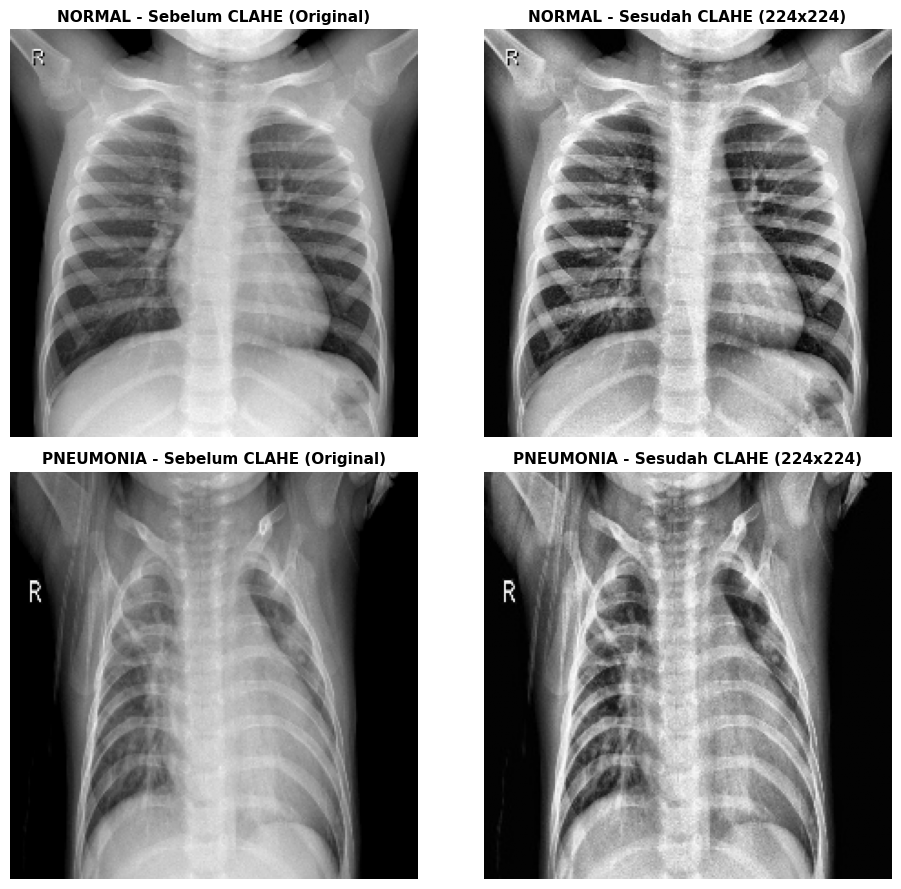

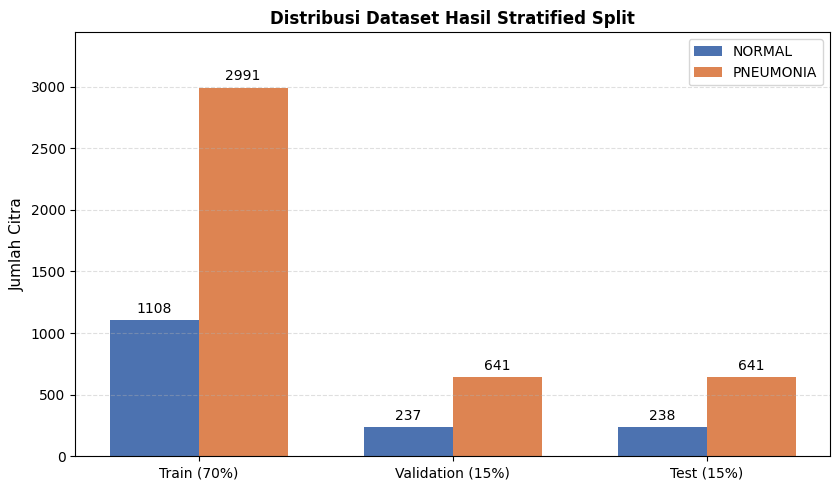

In [6]:
import random
import matplotlib.pyplot as plt

# 1. Visualisasi Before vs After CLAHE (Sampel Normal & Pneumonia)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
random.seed(42)

for row_idx, class_name in enumerate(CLASSES):
    # Ambil 1 sampel acak dari folder train yang sudah diproses
    processed_files = sorted(glob.glob(os.path.join(BASE_SPLIT_DIR, "train", class_name, "*.jpg")))
    sample_proc_path = random.choice(processed_files)
    
    # Ambil indeks dari nama file (contoh: train_123.jpg -> 123) untuk mencocokkan dengan X_train
    idx = int(os.path.basename(sample_proc_path).split("_")[1].split(".")[0])
    orig_path = X_train[idx]
    
    # Baca gambar asli (resize saja tanpa CLAHE untuk perbandingan adil)
    img_orig = cv2.imread(orig_path, cv2.IMREAD_GRAYSCALE)
    img_orig = cv2.resize(img_orig, IMG_SIZE)
    
    # Baca gambar hasil CLAHE
    img_clahe = cv2.imread(sample_proc_path, cv2.IMREAD_GRAYSCALE)
    
    # Plot Sebelum CLAHE
    axes[row_idx, 0].imshow(img_orig, cmap="gray")
    axes[row_idx, 0].set_title(f"{class_name} - Sebelum CLAHE (Original)", fontsize=11, fontweight="bold")
    axes[row_idx, 0].axis("off")
    
    # Plot Sesudah CLAHE
    axes[row_idx, 1].imshow(img_clahe, cmap="gray")
    axes[row_idx, 1].set_title(f"{class_name} - Sesudah CLAHE (224x224)", fontsize=11, fontweight="bold")
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/hasil_preprocessing_clahe.png", dpi=300)
plt.show()

# 2. Visualisasi Grafik Distribusi Dataset (Train, Val, Test)
splits = ["Train (70%)", "Validation (15%)", "Test (15%)"]
normal_counts = [y_train.count(0), y_val.count(0), y_test.count(0)]
pneumonia_counts = [y_train.count(1), y_val.count(1), y_test.count(1)]

x = np.arange(len(splits))
width = 0.35

fig, ax = plt.subplots(figsize=(8.5, 5))
rects1 = ax.bar(x - width/2, normal_counts, width, label="NORMAL", color="#4C72B0")
rects2 = ax.bar(x + width/2, pneumonia_counts, width, label="PNEUMONIA", color="#DD8452")

ax.set_ylabel("Jumlah Citra", fontsize=11)
ax.set_title("Distribusi Dataset Hasil Stratified Split", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(splits, fontsize=10)
ax.set_ylim(0, max(pneumonia_counts) * 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Tambahkan label angka di atas setiap batang grafik
ax.bar_label(rects1, padding=3, fontsize=10)
ax.bar_label(rects2, padding=3, fontsize=10)

plt.tight_layout()
plt.savefig("/kaggle/working/distribusi_split_dataset.png", dpi=300)
plt.show()